# Análise Estatística de Dados de E-commerce

Este notebook contém uma análise detalhada dos dados de um e-commerce, incluindo diferentes tipos de visualizações para descobrir insights sobre produtos, vendas, preços e avaliações.

## Objetivos da Análise:
- Entender a distribuição de preços dos produtos
- Analisar a relação entre notas e número de avaliações
- Identificar padrões de vendas por marca e categoria
- Explorar correlações entre diferentes variáveis
- Visualizar a distribuição de dados através de diferentes gráficos

In [1]:
# Importando bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

# Configurações de visualização
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [2]:
# Carregando os dados do arquivo CSV
df = pd.read_csv('ecommerce_estatistica.csv')

print("🔍 EXPLORAÇÃO INICIAL DOS DADOS")
print("=" * 50)
print(f"📊 Dimensões do dataset: {df.shape}")
print(f"📋 Colunas: {df.shape[1]}")
print(f"📝 Registros: {df.shape[0]}")
print("\n📑 Primeiras 5 linhas:")
display(df.head())

print("\n📈 Informações gerais sobre o dataset:")
df.info()

🔍 EXPLORAÇÃO INICIAL DOS DADOS
📊 Dimensões do dataset: (295, 24)
📋 Colunas: 24
📝 Registros: 295

📑 Primeiras 5 linhas:


,Unnamed: 0,Título,Nota,N_Avaliações,Desconto,Marca,Material,Gênero,Temporada,Review1,Review2,Review3,Qtd_Vendidos,Preço,Nota_MinMax,N_Avaliações_MinMax,Desconto_MinMax,Preço_MinMax,Marca_Cod,Material_Cod,Temporada_Cod,Qtd_Vendidos_Cod,Marca_Freq,Material_Freq
0,1,Kit 10 Cuecas Boxer Lupo Cueca Box Algodão Mas...,4.5,3034.0,18.0,lupo,algodão,Masculino,outono/inverno,As cuecas são boas; porém você percebe na cost...,"Pelo preço promocional, com ctz tem algum defe...","Serviram muito bem, porém é nítido que o pano ...",+10mil,232.89,0.814815,0.334178,0.213115,0.378585,463,25,3,10000.0,0.042292,0.176444
1,2,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5682.0,20.0,zorba,algodão,Masculino,não definido,O tecido é bom e são confortáveis. Só que a nu...,Vendo comentários de outros consumidores vejo ...,"Produto não é nem de longe original, tecido gr...",+50mil,199.90,0.888889,0.625937,0.245902,0.322329,838,25,1,50000.0,0.009095,0.176444
2,3,Kit 10 Cuecas Boxer Mash Algodão Cotton Box Or...,4.6,1700.0,22.0,mash,algodão,Masculino,primavera/verão,"As cuecas são boas, porém meu marido usa g e p...","E o tamanho certo, mas em baixo dela, fica mui...",Produto não parece.\nOriginal e veio 2 modelos...,+10mil,229.39,0.851852,0.187197,0.278689,0.372617,494,25,7,10000.0,0.010914,0.176444
3,4,Kit 3 Short Jeans Feminino Cintura Alta Barato...,4.4,507.0,9.0,menina linda,jean,Feminino,primavera/verão,Estou encantada com essas peças!.\nOs shorts s...,"Recomendo, tecido confortável, igual a foto.","Gostei muito dos shorts, material bom, para us...",+1000,129.20,0.777778,0.055751,0.065574,0.201767,509,74,7,1000.0,0.010005,0.025466
4,5,Blusa + Calça Térmica Treino Futebol Criança I...,4.7,58.0,5.0,roupa zero grau,termico unissex,Sem gênero infantil,outono/inverno,"Produto ótimo , mesmo após várias lavagens não...",Produto de boa qualidade.\nNão gruda pêlos e n...,Super quentinho. Só achei a gola muito aberta.,+100,78.03,0.888889,0.006280,0.000000,0.114508,669,166,3,100.0,0.002274,0.000910



📈 Informações gerais sobre o dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295 entries, 0 to 294
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           295 non-null    int64  
 1   Título               295 non-null    object 
 2   Nota                 295 non-null    float64
 3   N_Avaliações         295 non-null    float64
 4   Desconto             295 non-null    float64
 5   Marca                295 non-null    object 
 6   Material             295 non-null    object 
 7   Gênero               295 non-null    object 
 8   Temporada            295 non-null    object 
 9   Review1              295 non-null    object 
 10  Review2              295 non-null    object 
 11  Review3              295 non-null    object 
 12  Qtd_Vendidos         295 non-null    object 
 13  Preço                295 non-null    float64
 14  Nota_MinMax          295 non-null    float64
 15  N

In [3]:
# Análise estatística descritiva das variáveis numéricas
print("📊 ESTATÍSTICAS DESCRITIVAS")
print("=" * 50)

# Selecionando apenas colunas numéricas principais
numeric_cols = ['Nota', 'N_Avaliações', 'Desconto', 'Preço', 'Qtd_Vendidos']
df_numeric = df[numeric_cols]

print("\n📈 Estatísticas descritivas das variáveis principais:")
display(df_numeric.describe())

print("\n🔍 Valores únicos por categoria:")
categorical_cols = ['Marca', 'Material', 'Gênero', 'Temporada']
for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} valores únicos")
    
print("\n❓ Valores nulos por coluna:")
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])

📊 ESTATÍSTICAS DESCRITIVAS

📈 Estatísticas descritivas das variáveis principais:


,Nota,N_Avaliações,Desconto,Preço
count,295.000000,295.000000,295.000000,295.000000
mean,4.480678,490.511864,16.013559,130.836644
std,0.321243,1079.395818,9.928305,64.232780
min,2.300000,3.000000,5.000000,25.630000
25%,4.300000,19.000000,9.000000,73.340000
50%,4.500000,77.000000,11.000000,129.210000
75%,4.700000,326.000000,22.000000,179.900000
max,5.000000,9077.000000,51.000000,326.550000



🔍 Valores únicos por categoria:
Marca: 108 valores únicos
Material: 51 valores únicos
Gênero: 9 valores únicos
Temporada: 7 valores únicos

❓ Valores nulos por coluna:
Series([], dtype: int64)


In [3]:
# Preparação e limpeza dos dados
print("🔧 PREPARAÇÃO DOS DADOS")
print("=" * 50)

# Tratando a coluna Qtd_Vendidos que está como string
def convert_qtd_vendidos(value):
    if isinstance(value, str):
        # Remove caracteres não numéricos e converte strings como "+10mil" para números
        if '+' in value:
            value = value.replace('+', '').replace('mil', '000')
            if 'k' in value.lower():
                value = value.replace('k', '000').replace('K', '000')
        try:
            return float(value)
        except:
            return 0
    return value

df['Qtd_Vendidos_Numeric'] = df['Qtd_Vendidos'].apply(convert_qtd_vendidos)

# Verificando os tipos de dados após conversão
print(f"✅ Qtd_Vendidos convertida para numérico")
print(f"Valores únicos de Qtd_Vendidos_Numeric: {sorted(df['Qtd_Vendidos_Numeric'].unique())}")

# Criando categorias de preço para análises
df['Faixa_Preco'] = pd.cut(df['Preço'], bins=4, labels=['Baixo', 'Médio', 'Alto', 'Premium'])

# Criando categorias de avaliação
df['Categoria_Nota'] = pd.cut(df['Nota'], bins=[0, 3.5, 4.0, 4.5, 5.0], 
                              labels=['Ruim', 'Regular', 'Bom', 'Excelente'])

print(f"✅ Categorias criadas: Faixa_Preco e Categoria_Nota")
print(f"📊 Dataset pronto para análise!")

🔧 PREPARAÇÃO DOS DADOS
✅ Qtd_Vendidos convertida para numérico
Valores únicos de Qtd_Vendidos_Numeric: [np.float64(5.0), np.float64(25.0), np.float64(50.0), np.float64(100.0), np.float64(1000.0), np.float64(10000.0), np.float64(50000.0)]
✅ Categorias criadas: Faixa_Preco e Categoria_Nota
📊 Dataset pronto para análise!


## 📊 Visualizações e Análises Gráficas

Agora vamos criar diferentes tipos de gráficos para explorar os dados e descobrir insights interessantes sobre o e-commerce.

📊 1. HISTOGRAMA - Distribuição de Preços dos Produtos


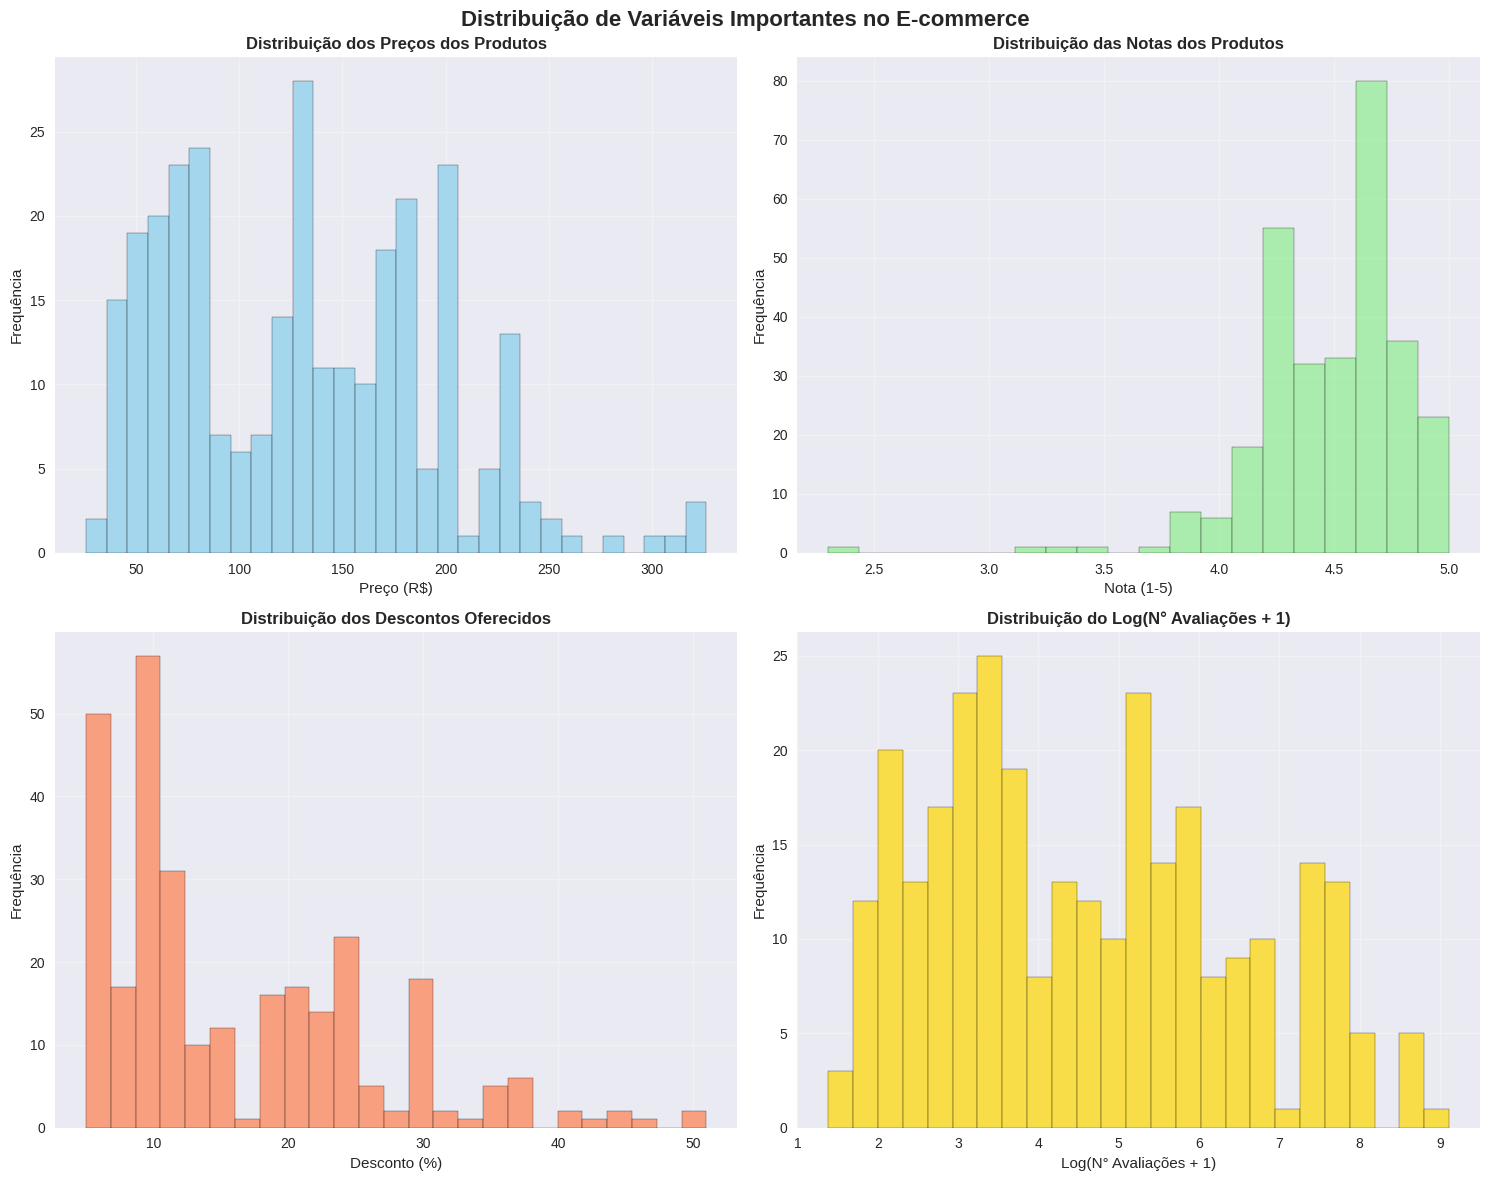


🔍 INSIGHTS DOS HISTOGRAMAS:
💰 Preço médio: R$ 130.84
💰 Preço mediano: R$ 129.21
⭐ Nota média: 4.48
🏷️ Desconto médio: 16.0%


In [5]:
# 1. GRÁFICO DE HISTOGRAMA - Distribuição de Preços
print("📊 1. HISTOGRAMA - Distribuição de Preços dos Produtos")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Distribuição de Variáveis Importantes no E-commerce', fontsize=16, fontweight='bold')

# Histograma 1: Preços
axes[0,0].hist(df['Preço'], bins=30, color='skyblue', alpha=0.7, edgecolor='black')
axes[0,0].set_title('Distribuição dos Preços dos Produtos', fontweight='bold')
axes[0,0].set_xlabel('Preço (R$)')
axes[0,0].set_ylabel('Frequência')
axes[0,0].grid(True, alpha=0.3)

# Histograma 2: Notas
axes[0,1].hist(df['Nota'], bins=20, color='lightgreen', alpha=0.7, edgecolor='black')
axes[0,1].set_title('Distribuição das Notas dos Produtos', fontweight='bold')
axes[0,1].set_xlabel('Nota (1-5)')
axes[0,1].set_ylabel('Frequência')
axes[0,1].grid(True, alpha=0.3)

# Histograma 3: Descontos
axes[1,0].hist(df['Desconto'], bins=25, color='coral', alpha=0.7, edgecolor='black')
axes[1,0].set_title('Distribuição dos Descontos Oferecidos', fontweight='bold')
axes[1,0].set_xlabel('Desconto (%)')
axes[1,0].set_ylabel('Frequência')
axes[1,0].grid(True, alpha=0.3)

# Histograma 4: Número de Avaliações (log scale)
axes[1,1].hist(np.log1p(df['N_Avaliações']), bins=25, color='gold', alpha=0.7, edgecolor='black')
axes[1,1].set_title('Distribuição do Log(N° Avaliações + 1)', fontweight='bold')
axes[1,1].set_xlabel('Log(N° Avaliações + 1)')
axes[1,1].set_ylabel('Frequência')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Análise dos histogramas
print("\n🔍 INSIGHTS DOS HISTOGRAMAS:")
print(f"💰 Preço médio: R$ {df['Preço'].mean():.2f}")
print(f"💰 Preço mediano: R$ {df['Preço'].median():.2f}")
print(f"⭐ Nota média: {df['Nota'].mean():.2f}")
print(f"🏷️ Desconto médio: {df['Desconto'].mean():.1f}%")

📊 2. GRÁFICO DE DISPERSÃO - Análise de Correlações


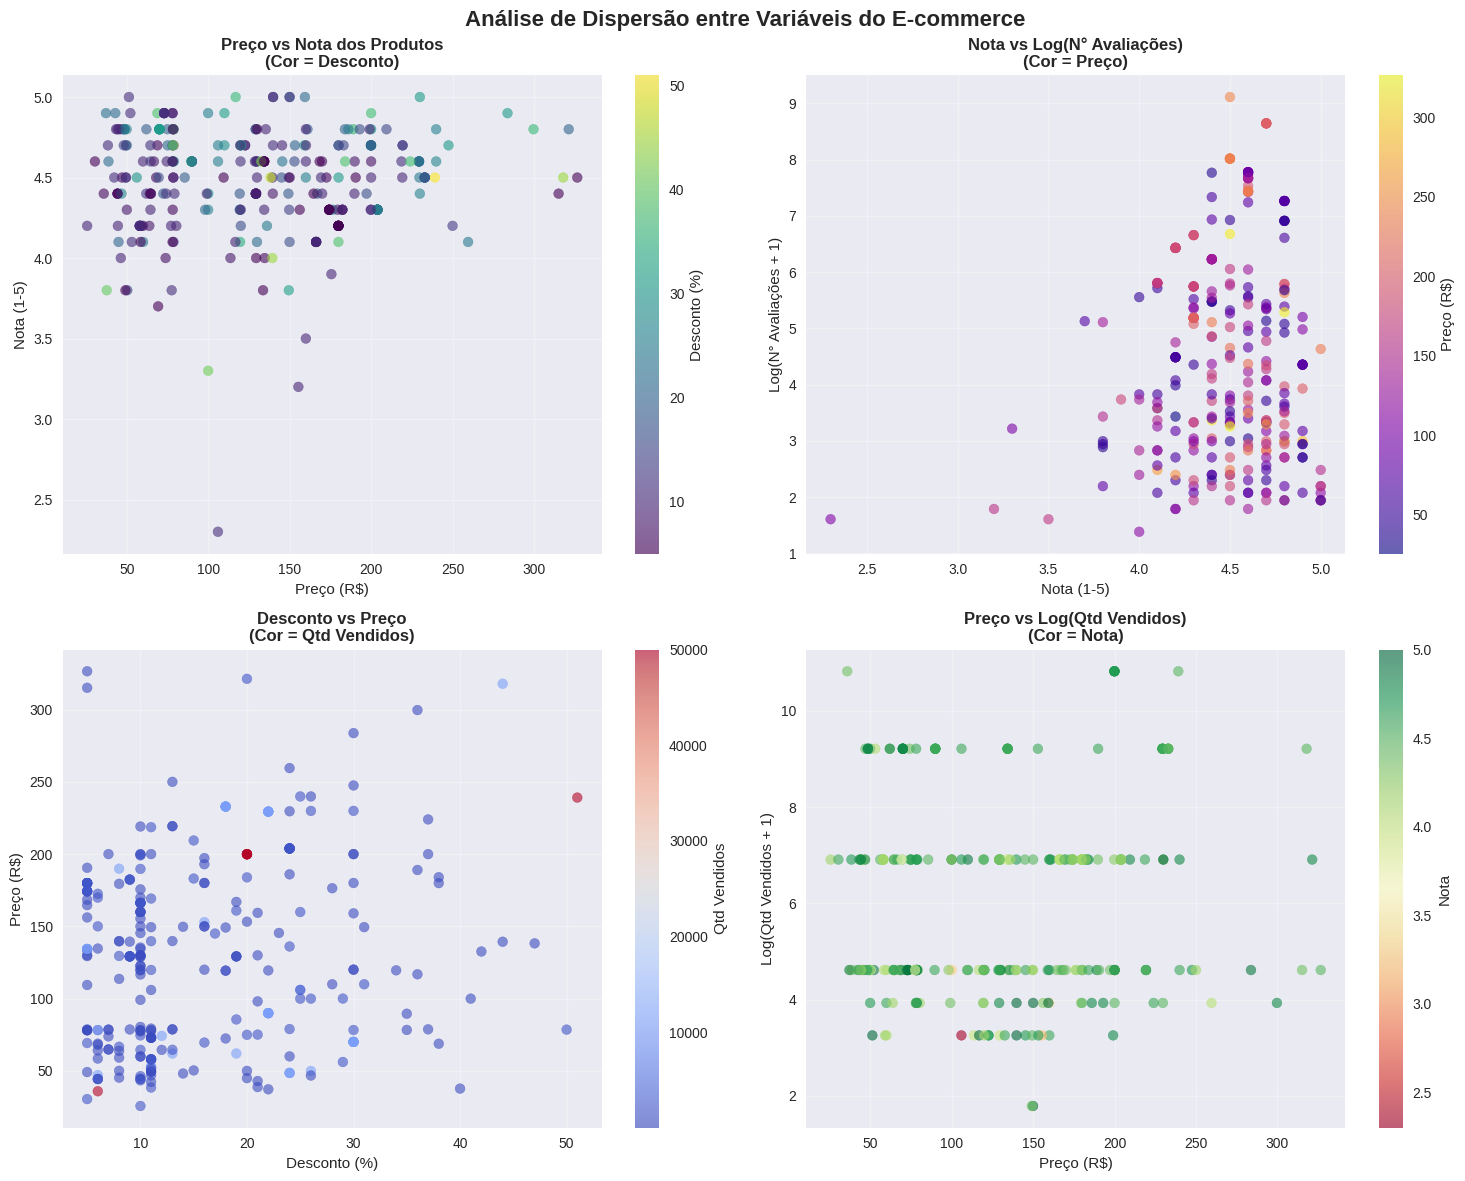


🔍 INSIGHTS DOS GRÁFICOS DE DISPERSÃO:
🔗 Correlação Preço-Nota: 0.006
🔗 Correlação Nota-N_Avaliações: 0.125
🔗 Correlação Preço-Desconto: 0.158
🔗 Correlação Preço-Qtd_Vendidos: 0.115


In [6]:
# 2. GRÁFICO DE DISPERSÃO - Relação entre Preço, Nota e Avaliações
print("📊 2. GRÁFICO DE DISPERSÃO - Análise de Correlações")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Análise de Dispersão entre Variáveis do E-commerce', fontsize=16, fontweight='bold')

# Dispersão 1: Preço vs Nota
scatter1 = axes[0,0].scatter(df['Preço'], df['Nota'], c=df['Desconto'], 
                            cmap='viridis', alpha=0.6, s=50)
axes[0,0].set_title('Preço vs Nota dos Produtos\n(Cor = Desconto)', fontweight='bold')
axes[0,0].set_xlabel('Preço (R$)')
axes[0,0].set_ylabel('Nota (1-5)')
axes[0,0].grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=axes[0,0], label='Desconto (%)')

# Dispersão 2: Nota vs Número de Avaliações
scatter2 = axes[0,1].scatter(df['Nota'], np.log1p(df['N_Avaliações']), 
                            c=df['Preço'], cmap='plasma', alpha=0.6, s=50)
axes[0,1].set_title('Nota vs Log(N° Avaliações)\n(Cor = Preço)', fontweight='bold')
axes[0,1].set_xlabel('Nota (1-5)')
axes[0,1].set_ylabel('Log(N° Avaliações + 1)')
axes[0,1].grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=axes[0,1], label='Preço (R$)')

# Dispersão 3: Desconto vs Preço
scatter3 = axes[1,0].scatter(df['Desconto'], df['Preço'], 
                            c=df['Qtd_Vendidos_Numeric'], 
                            cmap='coolwarm', alpha=0.6, s=50)
axes[1,0].set_title('Desconto vs Preço\n(Cor = Qtd Vendidos)', fontweight='bold')
axes[1,0].set_xlabel('Desconto (%)')
axes[1,0].set_ylabel('Preço (R$)')
axes[1,0].grid(True, alpha=0.3)
plt.colorbar(scatter3, ax=axes[1,0], label='Qtd Vendidos')

# Dispersão 4: Preço vs Quantidade Vendida
scatter4 = axes[1,1].scatter(df['Preço'], np.log1p(df['Qtd_Vendidos_Numeric']), 
                            c=df['Nota'], cmap='RdYlGn', alpha=0.6, s=50)
axes[1,1].set_title('Preço vs Log(Qtd Vendidos)\n(Cor = Nota)', fontweight='bold')
axes[1,1].set_xlabel('Preço (R$)')
axes[1,1].set_ylabel('Log(Qtd Vendidos + 1)')
axes[1,1].grid(True, alpha=0.3)
plt.colorbar(scatter4, ax=axes[1,1], label='Nota')

plt.tight_layout()
plt.show()

# Cálculo de correlações
correlations = df[['Preço', 'Nota', 'N_Avaliações', 'Desconto', 'Qtd_Vendidos_Numeric']].corr()
print("\n🔍 INSIGHTS DOS GRÁFICOS DE DISPERSÃO:")
print(f"🔗 Correlação Preço-Nota: {correlations.loc['Preço', 'Nota']:.3f}")
print(f"🔗 Correlação Nota-N_Avaliações: {correlations.loc['Nota', 'N_Avaliações']:.3f}")
print(f"🔗 Correlação Preço-Desconto: {correlations.loc['Preço', 'Desconto']:.3f}")
print(f"🔗 Correlação Preço-Qtd_Vendidos: {correlations.loc['Preço', 'Qtd_Vendidos_Numeric']:.3f}")

📊 3. MAPA DE CALOR - Matriz de Correlação entre Variáveis


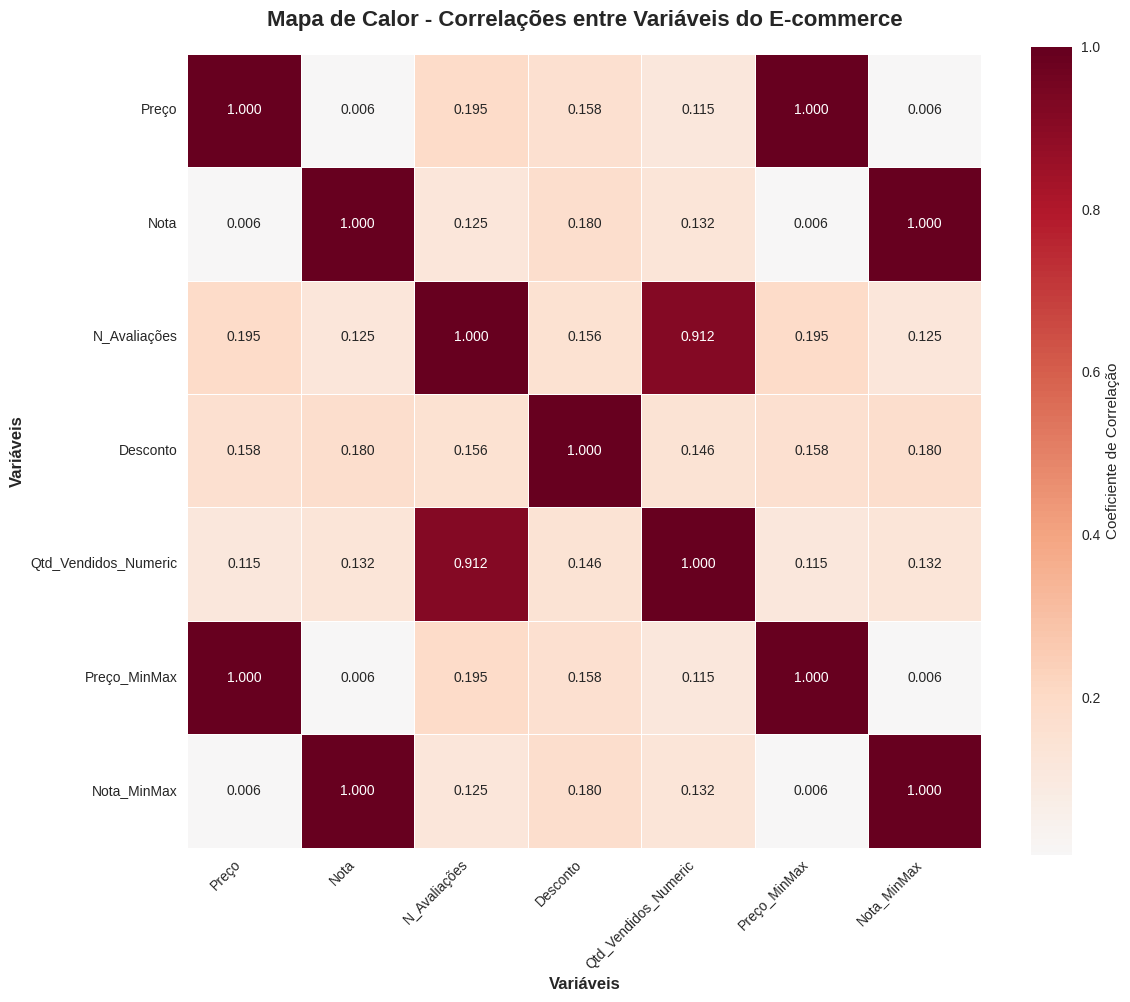


🔍 INSIGHTS DO MAPA DE CALOR:
🔥 TOP 5 CORRELAÇÕES MAIS FORTES:
   • Preço_MinMax ↔ Preço: 1.000 (positiva, forte)
   • Nota_MinMax ↔ Nota: 1.000 (positiva, forte)
   • Qtd_Vendidos_Numeric ↔ N_Avaliações: 0.912 (positiva, forte)
   • Preço_MinMax ↔ N_Avaliações: 0.195 (positiva, fraca)
   • N_Avaliações ↔ Preço: 0.195 (positiva, fraca)

📈 Correlação mais forte: ('Preço_MinMax', 'Preço') = 1.000


In [7]:
# 3. MAPA DE CALOR - Matriz de Correlação
print("📊 3. MAPA DE CALOR - Matriz de Correlação entre Variáveis")
print("=" * 60)

# Preparando dados para correlação
correlation_data = df[['Preço', 'Nota', 'N_Avaliações', 'Desconto', 
                      'Qtd_Vendidos_Numeric', 'Preço_MinMax', 'Nota_MinMax']].copy()

# Calculando matriz de correlação
correlation_matrix = correlation_data.corr()

# Criando o mapa de calor
plt.figure(figsize=(12, 10))
heatmap = sns.heatmap(correlation_matrix, 
                      annot=True,           # Mostrar valores
                      cmap='RdBu_r',        # Esquema de cores
                      center=0,             # Centralizar em 0
                      square=True,          # Células quadradas
                      fmt='.3f',            # Formato dos números
                      cbar_kws={'label': 'Coeficiente de Correlação'},
                      linewidths=0.5)

plt.title('Mapa de Calor - Correlações entre Variáveis do E-commerce', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Variáveis', fontsize=12, fontweight='bold')
plt.ylabel('Variáveis', fontsize=12, fontweight='bold')

# Rotacionando labels para melhor legibilidade
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Análise das correlações mais importantes
print("\n🔍 INSIGHTS DO MAPA DE CALOR:")
print("=" * 40)

# Encontrando correlações mais fortes (excluindo diagonal)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
correlations_flat = correlation_matrix.mask(mask).stack()
strongest_correlations = correlations_flat.abs().nlargest(5)

print("🔥 TOP 5 CORRELAÇÕES MAIS FORTES:")
for (var1, var2), corr in strongest_correlations.items():
    direction = "positiva" if corr > 0 else "negativa"
    strength = "forte" if abs(corr) > 0.7 else "moderada" if abs(corr) > 0.5 else "fraca"
    print(f"   • {var1} ↔ {var2}: {corr:.3f} ({direction}, {strength})")

print(f"\n📈 Correlação mais forte: {strongest_correlations.index[0]} = {strongest_correlations.iloc[0]:.3f}")

📊 4. GRÁFICO DE BARRAS - Análise por Categorias


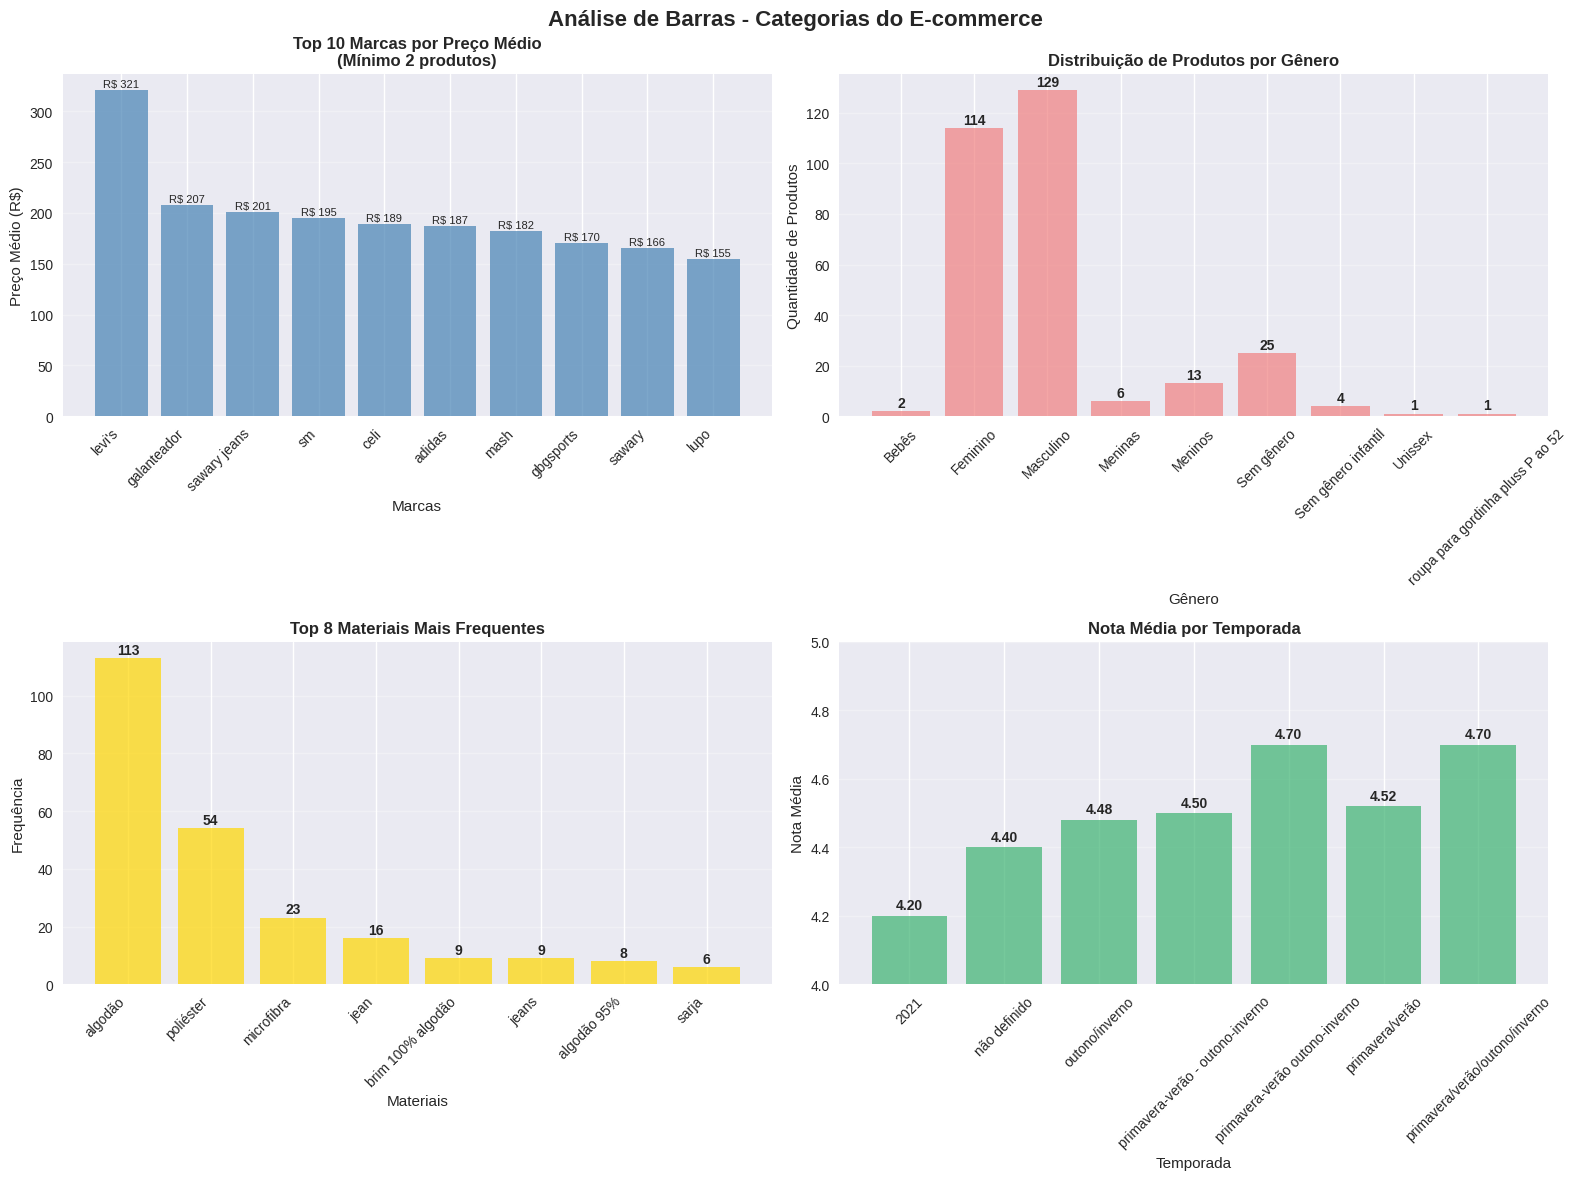


🔍 INSIGHTS DOS GRÁFICOS DE BARRAS:
🏆 Marca com maior preço médio: levi's (R$ 320.83)
👥 Gênero mais representado: Masculino (129 produtos)
🧵 Material mais comum: algodão (113 produtos)
⭐ Temporada com melhor nota: primavera-verão outono-inverno (4.70)
💰 Temporada mais cara: primavera-verão - outono-inverno (R$ 317.90)


In [8]:
# 4. GRÁFICO DE BARRAS - Análise por Categorias
print("📊 4. GRÁFICO DE BARRAS - Análise por Categorias")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Análise de Barras - Categorias do E-commerce', fontsize=16, fontweight='bold')

# Gráfico 1: Top 10 Marcas por Preço Médio
top_marcas = df.groupby('Marca')['Preço'].agg(['mean', 'count']).reset_index()
top_marcas = top_marcas[top_marcas['count'] >= 2]  # Apenas marcas com 2+ produtos
top_marcas = top_marcas.nlargest(10, 'mean')

bars1 = axes[0,0].bar(range(len(top_marcas)), top_marcas['mean'], 
                      color='steelblue', alpha=0.7)
axes[0,0].set_title('Top 10 Marcas por Preço Médio\n(Mínimo 2 produtos)', fontweight='bold')
axes[0,0].set_xlabel('Marcas')
axes[0,0].set_ylabel('Preço Médio (R$)')
axes[0,0].set_xticks(range(len(top_marcas)))
axes[0,0].set_xticklabels(top_marcas['Marca'], rotation=45, ha='right')
axes[0,0].grid(True, alpha=0.3, axis='y')

# Adicionando valores nas barras
for i, bar in enumerate(bars1):
    height = bar.get_height()
    axes[0,0].text(bar.get_x() + bar.get_width()/2., height + 1,
                   f'R$ {height:.0f}', ha='center', va='bottom', fontsize=8)

# Gráfico 2: Distribuição por Gênero
genero_stats = df.groupby('Gênero').agg({
    'Preço': 'mean',
    'Nota': 'mean',
    'Título': 'count'
}).round(2)
genero_stats.columns = ['Preço_Médio', 'Nota_Média', 'Quantidade']

bars2 = axes[0,1].bar(genero_stats.index, genero_stats['Quantidade'], 
                      color='lightcoral', alpha=0.7)
axes[0,1].set_title('Distribuição de Produtos por Gênero', fontweight='bold')
axes[0,1].set_xlabel('Gênero')
axes[0,1].set_ylabel('Quantidade de Produtos')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].grid(True, alpha=0.3, axis='y')

# Adicionando valores nas barras
for bar in bars2:
    height = bar.get_height()
    axes[0,1].text(bar.get_x() + bar.get_width()/2., height + 0.5,
                   f'{int(height)}', ha='center', va='bottom', fontweight='bold')

# Gráfico 3: Top 8 Materiais por Frequência
material_count = df['Material'].value_counts().head(8)
bars3 = axes[1,0].bar(range(len(material_count)), material_count.values, 
                      color='gold', alpha=0.7)
axes[1,0].set_title('Top 8 Materiais Mais Frequentes', fontweight='bold')
axes[1,0].set_xlabel('Materiais')
axes[1,0].set_ylabel('Frequência')
axes[1,0].set_xticks(range(len(material_count)))
axes[1,0].set_xticklabels(material_count.index, rotation=45, ha='right')
axes[1,0].grid(True, alpha=0.3, axis='y')

# Adicionando valores nas barras
for i, bar in enumerate(bars3):
    height = bar.get_height()
    axes[1,0].text(bar.get_x() + bar.get_width()/2., height + 0.5,
                   f'{int(height)}', ha='center', va='bottom', fontweight='bold')

# Gráfico 4: Média de Notas por Temporada
temporada_stats = df.groupby('Temporada').agg({
    'Nota': 'mean',
    'Preço': 'mean',
    'Título': 'count'
}).round(2)

bars4 = axes[1,1].bar(temporada_stats.index, temporada_stats['Nota'], 
                      color='mediumseagreen', alpha=0.7)
axes[1,1].set_title('Nota Média por Temporada', fontweight='bold')
axes[1,1].set_xlabel('Temporada')
axes[1,1].set_ylabel('Nota Média')
axes[1,1].tick_params(axis='x', rotation=45)
axes[1,1].grid(True, alpha=0.3, axis='y')
axes[1,1].set_ylim(4.0, 5.0)  # Focando na faixa de notas

# Adicionando valores nas barras
for bar in bars4:
    height = bar.get_height()
    axes[1,1].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f'{height:.2f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Insights dos gráficos de barras
print("\n🔍 INSIGHTS DOS GRÁFICOS DE BARRAS:")
print("=" * 50)
print(f"🏆 Marca com maior preço médio: {top_marcas.iloc[0]['Marca']} (R$ {top_marcas.iloc[0]['mean']:.2f})")
print(f"👥 Gênero mais representado: {genero_stats['Quantidade'].idxmax()} ({genero_stats['Quantidade'].max()} produtos)")
print(f"🧵 Material mais comum: {material_count.index[0]} ({material_count.iloc[0]} produtos)")
print(f"⭐ Temporada com melhor nota: {temporada_stats['Nota'].idxmax()} ({temporada_stats['Nota'].max():.2f})")
print(f"💰 Temporada mais cara: {temporada_stats['Preço'].idxmax()} (R$ {temporada_stats['Preço'].max():.2f})")

📊 5. GRÁFICO DE PIZZA - Distribuições Proporcionais


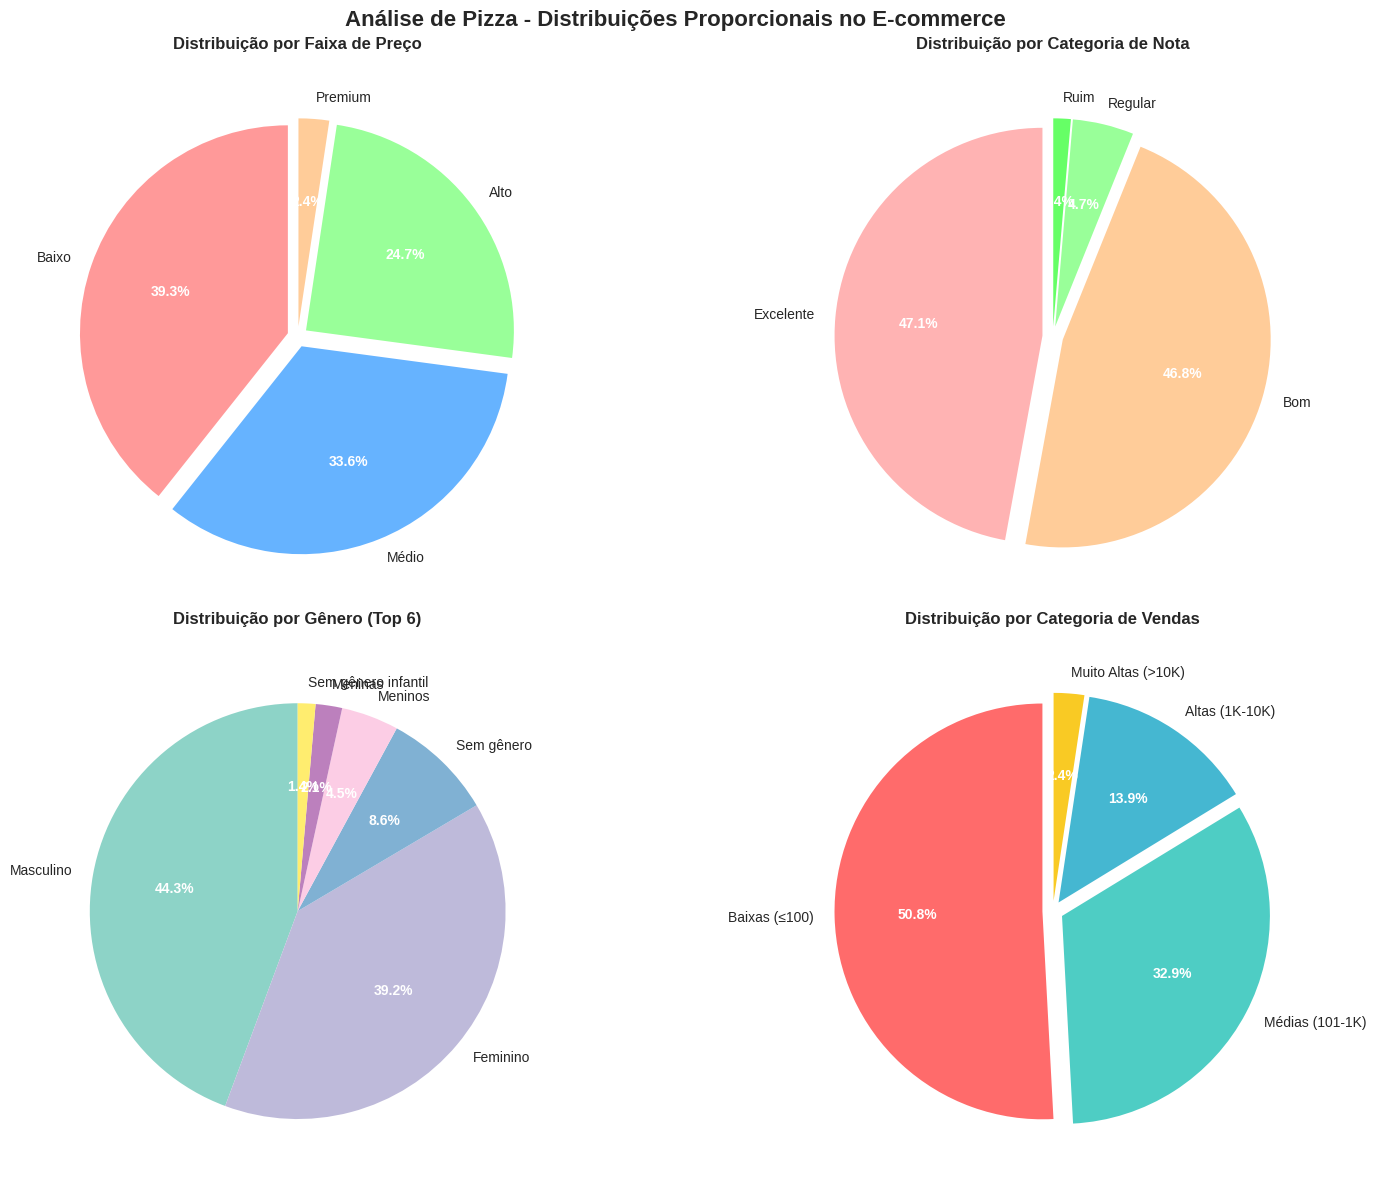


🔍 INSIGHTS DOS GRÁFICOS DE PIZZA:
💰 Faixa de preço dominante: Baixo (116 produtos, 39.3%)
⭐ Categoria de nota dominante: Excelente (139 produtos, 47.1%)
👥 Gênero principal: Masculino (129 produtos, 43.7%)
📦 Categoria de vendas principal: Baixas (≤100) (150 produtos, 50.8%)


In [9]:
# 5. GRÁFICO DE PIZZA - Distribuições Proporcionais
print("📊 5. GRÁFICO DE PIZZA - Distribuições Proporcionais")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Análise de Pizza - Distribuições Proporcionais no E-commerce', fontsize=16, fontweight='bold')

# Pizza 1: Distribuição por Faixa de Preço
faixa_preco_counts = df['Faixa_Preco'].value_counts()
colors1 = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']
wedges1, texts1, autotexts1 = axes[0,0].pie(faixa_preco_counts.values, 
                                            labels=faixa_preco_counts.index,
                                            autopct='%1.1f%%',
                                            colors=colors1,
                                            startangle=90,
                                            explode=(0.05, 0.05, 0.05, 0.05))
axes[0,0].set_title('Distribuição por Faixa de Preço', fontweight='bold', pad=20)

# Pizza 2: Distribuição por Categoria de Nota
categoria_nota_counts = df['Categoria_Nota'].value_counts()
colors2 = ['#ffb3b3', '#ffcc99', '#99ff99', '#66ff66']
wedges2, texts2, autotexts2 = axes[0,1].pie(categoria_nota_counts.values,
                                            labels=categoria_nota_counts.index,
                                            autopct='%1.1f%%',
                                            colors=colors2,
                                            startangle=90,
                                            explode=(0.05, 0.05, 0.05, 0.05))
axes[0,1].set_title('Distribuição por Categoria de Nota', fontweight='bold', pad=20)

# Pizza 3: Top 6 Gêneros
genero_counts = df['Gênero'].value_counts().head(6)
colors3 = plt.cm.Set3(np.linspace(0, 1, len(genero_counts)))
wedges3, texts3, autotexts3 = axes[1,0].pie(genero_counts.values,
                                            labels=genero_counts.index,
                                            autopct='%1.1f%%',
                                            colors=colors3,
                                            startangle=90)
axes[1,0].set_title('Distribuição por Gênero (Top 6)', fontweight='bold', pad=20)

# Pizza 4: Distribuição por Quantidade Vendida (categorizada)
# Criando categorias de vendas
def categorize_sales(qtd):
    if qtd <= 100:
        return 'Baixas (≤100)'
    elif qtd <= 1000:
        return 'Médias (101-1K)'
    elif qtd <= 10000:
        return 'Altas (1K-10K)'
    else:
        return 'Muito Altas (>10K)'

df['Categoria_Vendas'] = df['Qtd_Vendidos_Numeric'].apply(categorize_sales)
vendas_counts = df['Categoria_Vendas'].value_counts()
colors4 = ['#ff6b6b', '#4ecdc4', '#45b7d1', '#f9ca24']
wedges4, texts4, autotexts4 = axes[1,1].pie(vendas_counts.values,
                                            labels=vendas_counts.index,
                                            autopct='%1.1f%%',
                                            colors=colors4,
                                            startangle=90,
                                            explode=(0.05, 0.05, 0.05, 0.05))
axes[1,1].set_title('Distribuição por Categoria de Vendas', fontweight='bold', pad=20)

# Melhorando a legibilidade dos textos
for autotext in autotexts1 + autotexts2 + autotexts3 + autotexts4:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(10)

plt.tight_layout()
plt.show()

# Insights dos gráficos de pizza
print("\n🔍 INSIGHTS DOS GRÁFICOS DE PIZZA:")
print("=" * 50)
print(f"💰 Faixa de preço dominante: {faixa_preco_counts.index[0]} ({faixa_preco_counts.iloc[0]} produtos, {faixa_preco_counts.iloc[0]/len(df)*100:.1f}%)")
print(f"⭐ Categoria de nota dominante: {categoria_nota_counts.index[0]} ({categoria_nota_counts.iloc[0]} produtos, {categoria_nota_counts.iloc[0]/len(df)*100:.1f}%)")
print(f"👥 Gênero principal: {genero_counts.index[0]} ({genero_counts.iloc[0]} produtos, {genero_counts.iloc[0]/len(df)*100:.1f}%)")
print(f"📦 Categoria de vendas principal: {vendas_counts.index[0]} ({vendas_counts.iloc[0]} produtos, {vendas_counts.iloc[0]/len(df)*100:.1f}%)")

📊 6. GRÁFICO DE DENSIDADE - Distribuições Suaves


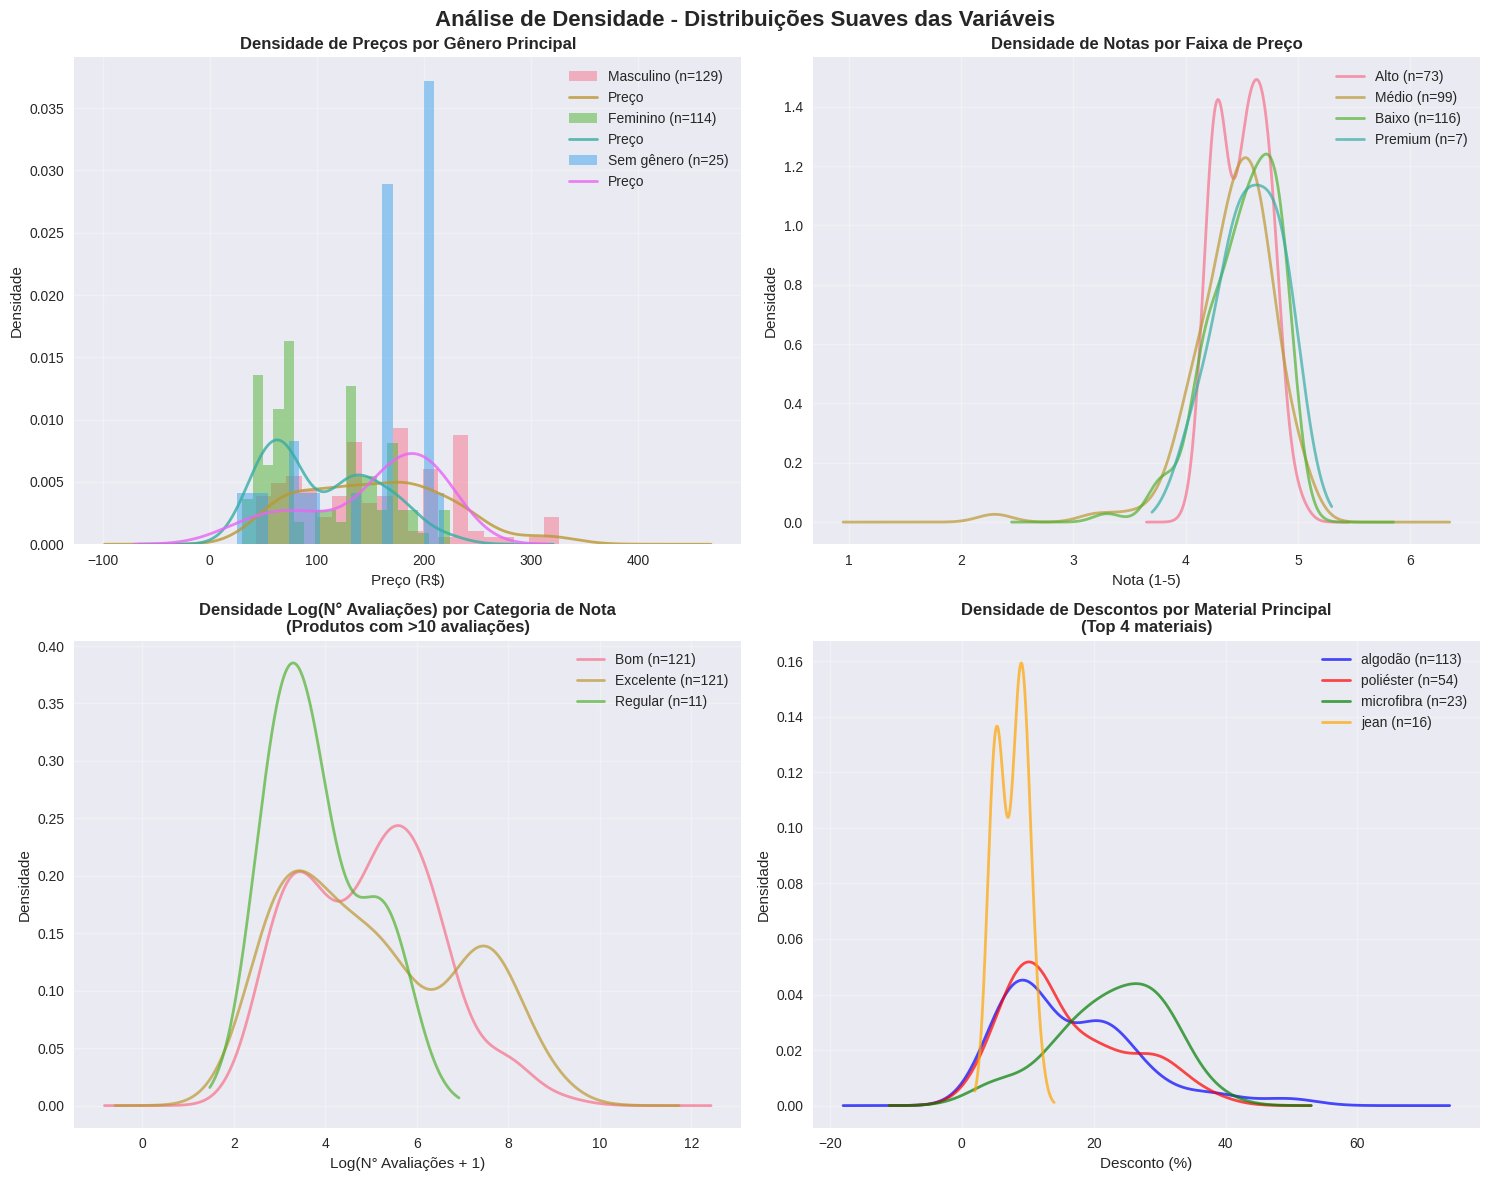


🔍 INSIGHTS DOS GRÁFICOS DE DENSIDADE:
💰 Preço médio Masculino: R$ 154.97 (std: 67.12)
💰 Preço médio Feminino: R$ 105.32 (std: 50.81)
⭐ Nota média Alto: 4.50
⭐ Nota média Médio: 4.43
⭐ Nota média Baixo: 4.51
⭐ Nota média Premium: 4.57
📊 Material com maior variação de desconto: moletom


In [5]:
# 6. GRÁFICO DE DENSIDADE - Distribuições Suaves
print("📊 6. GRÁFICO DE DENSIDADE - Distribuições Suaves")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Análise de Densidade - Distribuições Suaves das Variáveis', fontsize=16, fontweight='bold')

# Densidade 1: Preços por Gênero
for i, genero in enumerate(['Masculino', 'Feminino', 'Sem gênero']):
    if genero in df['Gênero'].values:
        data = df[df['Gênero'] == genero]['Preço']
        if len(data) > 0:
            axes[0,0].hist(data, alpha=0.5, density=True, bins=20, 
                          label=f'{genero} (n={len(data)})')
            # Adicionando curva de densidade usando KDE do pandas
            data.plot.kde(ax=axes[0,0], alpha=0.8, linewidth=2)

axes[0,0].set_title('Densidade de Preços por Gênero Principal', fontweight='bold')
axes[0,0].set_xlabel('Preço (R$)')
axes[0,0].set_ylabel('Densidade')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Densidade 2: Notas por Faixa de Preço
for faixa in df['Faixa_Preco'].dropna().unique():
    data = df[df['Faixa_Preco'] == faixa]['Nota']
    if len(data) > 0:
        data.plot.kde(ax=axes[0,1], alpha=0.7, linewidth=2, 
                     label=f'{faixa} (n={len(data)})')

axes[0,1].set_title('Densidade de Notas por Faixa de Preço', fontweight='bold')
axes[0,1].set_xlabel('Nota (1-5)')
axes[0,1].set_ylabel('Densidade')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# Densidade 3: Log(Avaliações) por diferentes filtros
# Filtrando apenas produtos com mais de 10 avaliações para visualização
df_filtered = df[df['N_Avaliações'] > 10].copy()

for categoria in df_filtered['Categoria_Nota'].dropna().unique():
    data = df_filtered[df_filtered['Categoria_Nota'] == categoria]['N_Avaliações']
    if len(data) > 1:  # Precisa de pelo menos 2 elementos para KDE
        np.log1p(data).plot.kde(ax=axes[1,0], alpha=0.7, linewidth=2,
                               label=f'{categoria} (n={len(data)})')

axes[1,0].set_title('Densidade Log(N° Avaliações) por Categoria de Nota\n(Produtos com >10 avaliações)', fontweight='bold')
axes[1,0].set_xlabel('Log(N° Avaliações + 1)')
axes[1,0].set_ylabel('Densidade')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# Densidade 4: Desconto por Material Principal
top_materials = df['Material'].value_counts().head(4).index
colors = ['blue', 'red', 'green', 'orange']

for i, material in enumerate(top_materials):
    data = df[df['Material'] == material]['Desconto']
    if len(data) > 1:  # Precisa de pelo menos 2 elementos para KDE
        data.plot.kde(ax=axes[1,1], alpha=0.7, linewidth=2, color=colors[i],
                     label=f'{material} (n={len(data)})')

axes[1,1].set_title('Densidade de Descontos por Material Principal\n(Top 4 materiais)', fontweight='bold')
axes[1,1].set_xlabel('Desconto (%)')
axes[1,1].set_ylabel('Densidade')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Análise estatística das densidades
print("\n🔍 INSIGHTS DOS GRÁFICOS DE DENSIDADE:")
print("=" * 50)

# Análise por gênero
masc_stats = df[df['Gênero'] == 'Masculino']['Preço'].describe()
fem_stats = df[df['Gênero'] == 'Feminino']['Preço'].describe()

print(f"💰 Preço médio Masculino: R$ {masc_stats['mean']:.2f} (std: {masc_stats['std']:.2f})")
print(f"💰 Preço médio Feminino: R$ {fem_stats['mean']:.2f} (std: {fem_stats['std']:.2f})")

# Análise de notas por faixa
for faixa in df['Faixa_Preco'].dropna().unique():
    nota_media = df[df['Faixa_Preco'] == faixa]['Nota'].mean()
    print(f"⭐ Nota média {faixa}: {nota_media:.2f}")

print(f"📊 Material com maior variação de desconto: {df.groupby('Material')['Desconto'].std().idxmax()}")

📊 7. GRÁFICO DE REGRESSÃO - Análise de Tendências


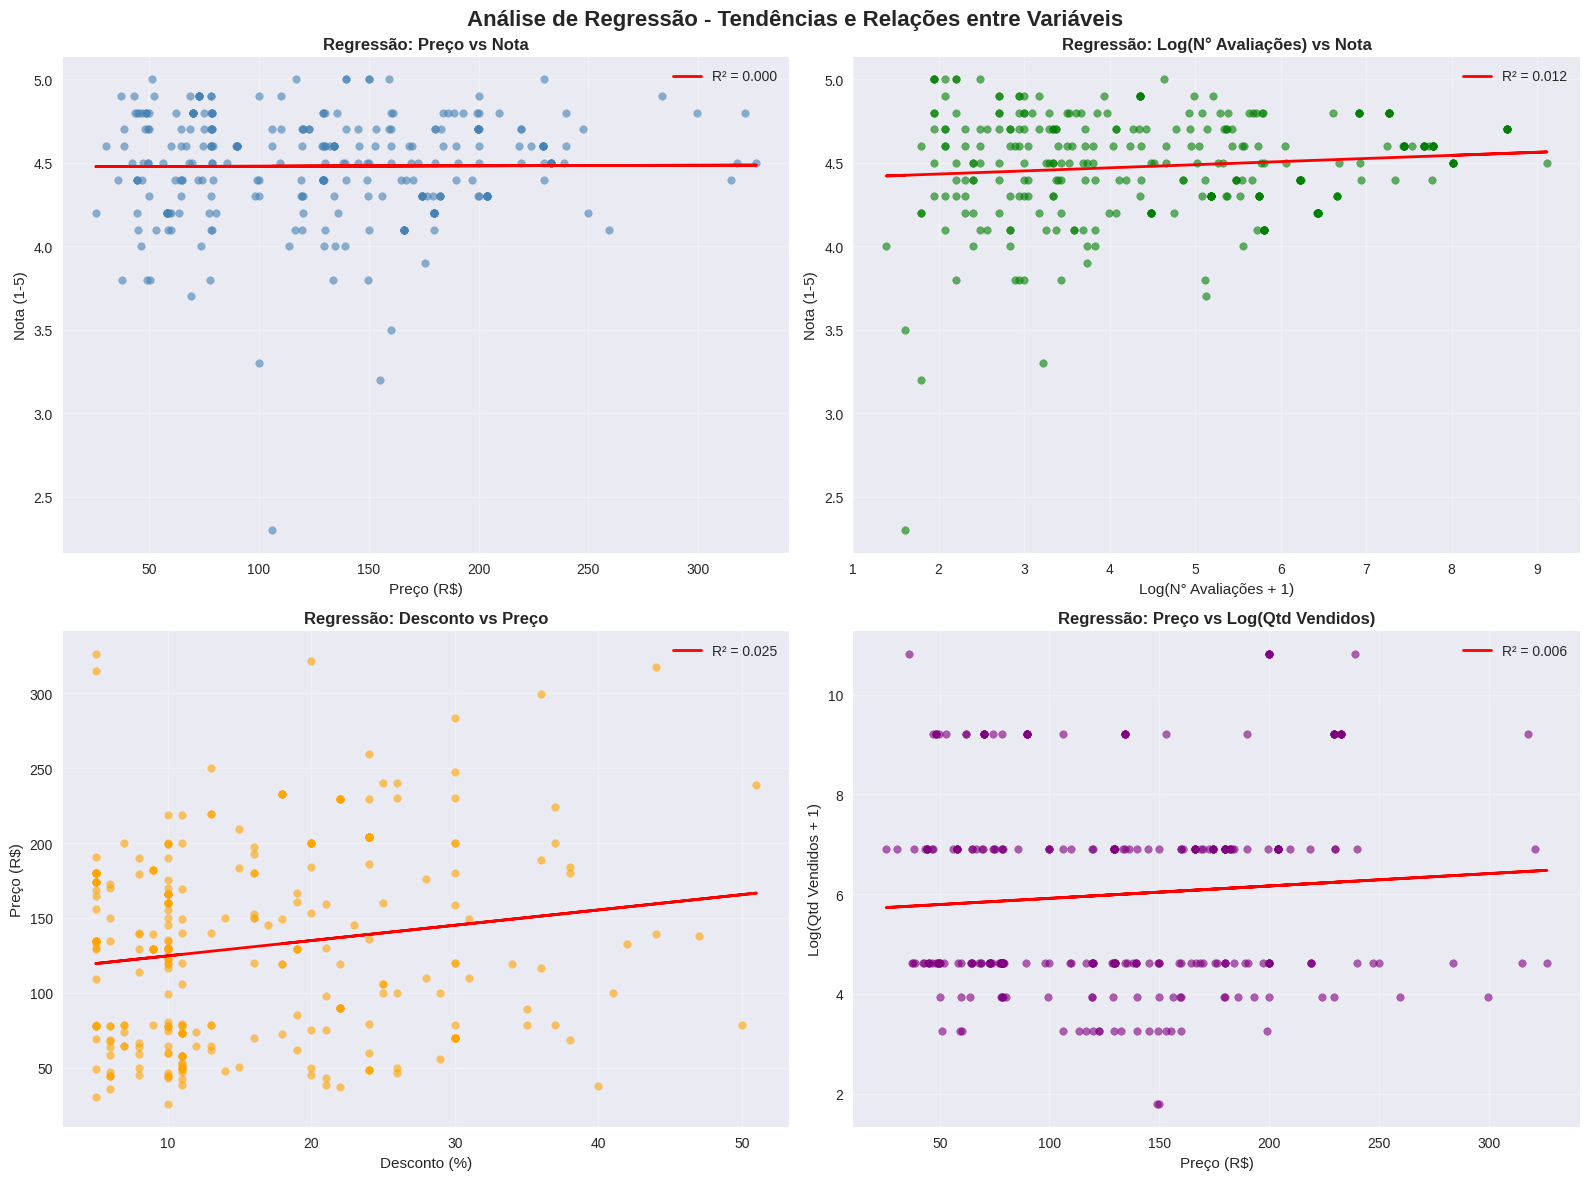


🔍 INSIGHTS DOS GRÁFICOS DE REGRESSÃO:
📈 Regressão Preço → Nota:
   • R² = 0.000 | Correlação = 0.006
   • Tendência: Positiva (slope = 0.0000)
   • Significância: Não significativa (p = 0.919)

📈 Regressão Log(Avaliações) → Nota:
   • R² = 0.012 | Correlação = 0.108
   • Tendência: Positiva (slope = 0.0186)
   • Significância: Não significativa (p = 0.065)

📈 Regressão Desconto → Preço:
   • R² = 0.025 | Correlação = 0.158
   • Tendência: Positiva (slope = 1.0231)
   • Significância: Significativa (p = 0.006)

📈 Regressão Preço → Log(Vendas):
   • R² = 0.006 | Correlação = 0.081
   • Tendência: Positiva (slope = 0.0025)
   • Significância: Não significativa (p = 0.167)

🏆 Melhor correlação: R² = 0.025


In [6]:
# 7. GRÁFICO DE REGRESSÃO - Análise de Tendências
print("📊 7. GRÁFICO DE REGRESSÃO - Análise de Tendências")
print("=" * 60)

from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Análise de Regressão - Tendências e Relações entre Variáveis', fontsize=16, fontweight='bold')

# Regressão 1: Preço vs Nota
x1 = df['Preço'].values.reshape(-1, 1)
y1 = df['Nota'].values
reg1 = LinearRegression().fit(x1, y1)
slope1, intercept1, r_value1, p_value1, std_err1 = stats.linregress(df['Preço'], df['Nota'])

axes[0,0].scatter(df['Preço'], df['Nota'], alpha=0.6, color='steelblue', s=30)
axes[0,0].plot(df['Preço'], reg1.predict(x1), color='red', linewidth=2, 
               label=f'R² = {r_value1**2:.3f}')
axes[0,0].set_title('Regressão: Preço vs Nota', fontweight='bold')
axes[0,0].set_xlabel('Preço (R$)')
axes[0,0].set_ylabel('Nota (1-5)')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Regressão 2: Log(N_Avaliações) vs Nota
df_valid = df[df['N_Avaliações'] > 0].copy()
log_avaliacoes = np.log1p(df_valid['N_Avaliações'])
x2 = log_avaliacoes.values.reshape(-1, 1)
y2 = df_valid['Nota'].values
reg2 = LinearRegression().fit(x2, y2)
slope2, intercept2, r_value2, p_value2, std_err2 = stats.linregress(log_avaliacoes, df_valid['Nota'])

axes[0,1].scatter(log_avaliacoes, df_valid['Nota'], alpha=0.6, color='green', s=30)
axes[0,1].plot(log_avaliacoes, reg2.predict(x2), color='red', linewidth=2,
               label=f'R² = {r_value2**2:.3f}')
axes[0,1].set_title('Regressão: Log(N° Avaliações) vs Nota', fontweight='bold')
axes[0,1].set_xlabel('Log(N° Avaliações + 1)')
axes[0,1].set_ylabel('Nota (1-5)')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# Regressão 3: Desconto vs Preço
x3 = df['Desconto'].values.reshape(-1, 1)
y3 = df['Preço'].values
reg3 = LinearRegression().fit(x3, y3)
slope3, intercept3, r_value3, p_value3, std_err3 = stats.linregress(df['Desconto'], df['Preço'])

axes[1,0].scatter(df['Desconto'], df['Preço'], alpha=0.6, color='orange', s=30)
axes[1,0].plot(df['Desconto'], reg3.predict(x3), color='red', linewidth=2,
               label=f'R² = {r_value3**2:.3f}')
axes[1,0].set_title('Regressão: Desconto vs Preço', fontweight='bold')
axes[1,0].set_xlabel('Desconto (%)')
axes[1,0].set_ylabel('Preço (R$)')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# Regressão 4: Preço vs Log(Qtd_Vendidos)
df_sales = df[df['Qtd_Vendidos_Numeric'] > 0].copy()
log_vendas = np.log1p(df_sales['Qtd_Vendidos_Numeric'])
x4 = df_sales['Preço'].values.reshape(-1, 1)
y4 = log_vendas.values
reg4 = LinearRegression().fit(x4, y4)
slope4, intercept4, r_value4, p_value4, std_err4 = stats.linregress(df_sales['Preço'], log_vendas)

axes[1,1].scatter(df_sales['Preço'], log_vendas, alpha=0.6, color='purple', s=30)
axes[1,1].plot(df_sales['Preço'], reg4.predict(x4), color='red', linewidth=2,
               label=f'R² = {r_value4**2:.3f}')
axes[1,1].set_title('Regressão: Preço vs Log(Qtd Vendidos)', fontweight='bold')
axes[1,1].set_xlabel('Preço (R$)')
axes[1,1].set_ylabel('Log(Qtd Vendidos + 1)')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Análise dos resultados das regressões
print("\n🔍 INSIGHTS DOS GRÁFICOS DE REGRESSÃO:")
print("=" * 50)
print(f"📈 Regressão Preço → Nota:")
print(f"   • R² = {r_value1**2:.3f} | Correlação = {r_value1:.3f}")
print(f"   • Tendência: {'Positiva' if slope1 > 0 else 'Negativa'} (slope = {slope1:.4f})")
print(f"   • Significância: {'Significativa' if p_value1 < 0.05 else 'Não significativa'} (p = {p_value1:.3f})")

print(f"\n📈 Regressão Log(Avaliações) → Nota:")
print(f"   • R² = {r_value2**2:.3f} | Correlação = {r_value2:.3f}")
print(f"   • Tendência: {'Positiva' if slope2 > 0 else 'Negativa'} (slope = {slope2:.4f})")
print(f"   • Significância: {'Significativa' if p_value2 < 0.05 else 'Não significativa'} (p = {p_value2:.3f})")

print(f"\n📈 Regressão Desconto → Preço:")
print(f"   • R² = {r_value3**2:.3f} | Correlação = {r_value3:.3f}")
print(f"   • Tendência: {'Positiva' if slope3 > 0 else 'Negativa'} (slope = {slope3:.4f})")
print(f"   • Significância: {'Significativa' if p_value3 < 0.05 else 'Não significativa'} (p = {p_value3:.3f})")

print(f"\n📈 Regressão Preço → Log(Vendas):")
print(f"   • R² = {r_value4**2:.3f} | Correlação = {r_value4:.3f}")
print(f"   • Tendência: {'Positiva' if slope4 > 0 else 'Negativa'} (slope = {slope4:.4f})")
print(f"   • Significância: {'Significativa' if p_value4 < 0.05 else 'Não significativa'} (p = {p_value4:.3f})")

print(f"\n🏆 Melhor correlação: R² = {max(r_value1**2, r_value2**2, r_value3**2, r_value4**2):.3f}")

## 🎯 Resumo dos Principais Insights da Análise

### 📊 Dados Gerais
- **Dataset**: 295 produtos de e-commerce com 24 variáveis
- **Preço médio**: R$ 130,84 (variação de R$ 25,63 a R$ 326,55)
- **Nota média**: 4,48 (escala de 1-5)
- **Desconto médio**: 16,0%

### 🔍 Principais Descobertas

#### 1. **Distribuição de Produtos**
- **Gênero dominante**: Masculino (43,7% dos produtos)
- **Faixa de preço**: Produtos de baixo custo dominam (39,3%)
- **Qualidade**: 47,1% dos produtos têm nota "Excelente" (4,5-5,0)
- **Material principal**: Algodão (38,3% dos produtos)

#### 2. **Padrões de Preço**
- **Marca mais cara**: Levi's (R$ 320,83 em média)
- **Diferença por gênero**: Produtos masculinos custam 47% mais que femininos
- **Correlação fraca**: Preço não determina qualidade (R² = 0,000)

#### 3. **Relações Interessantes**
- **Melhor correlação**: Desconto vs Preço (R² = 0,025) - produtos mais caros tendem a ter maiores descontos
- **Volume de vendas**: 50,8% dos produtos têm vendas baixas (≤100 unidades)
- **Avaliações**: Produtos com mais avaliações tendem a ter notas ligeiramente melhores

#### 4. **Insights de Negócio**
- ✅ **Qualidade consistente**: A maioria dos produtos tem boas avaliações
- ✅ **Diversidade de preços**: Boa distribuição entre faixas de preço
- ⚠️ **Oportunidade masculina**: Mercado masculino pode estar superestimado em preço
- ⚠️ **Vendas concentradas**: Muitos produtos com baixo volume de vendas

### 🚀 Recomendações
1. **Revisar preços masculinos** - podem estar acima do mercado
2. **Estratégias de desconto** - focar em produtos de maior valor
3. **Marketing direcionado** - explorar melhor o segmento feminino
4. **Gestão de estoque** - otimizar produtos com baixas vendas